Celda 1 — Carga de datos, resolución de rutas y motor SQLite en memoria

In [1]:
import os
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Rutas relativas portables desde notebooks/
BASE_DIR = os.path.dirname(os.path.dirname(os.path.abspath("__file__")))
DATA_DIR = os.path.join(BASE_DIR, "data")
DOCS_IMG_DIR = os.path.join(BASE_DIR, "docs", "img")
OUTPUTS_DIR = os.path.join(BASE_DIR, "outputs")
os.makedirs(DOCS_IMG_DIR, exist_ok=True)
os.makedirs(OUTPUTS_DIR, exist_ok=True)

# Carga de datasets
df_orders = pd.read_csv(os.path.join(DATA_DIR, "olist_orders_dataset.csv"))
df_payments = pd.read_csv(os.path.join(DATA_DIR, "olist_order_payments_dataset.csv"))
df_customers = pd.read_csv(os.path.join(DATA_DIR, "olist_customers_dataset.csv"))

# Carga en base de datos relacional SQLite en memoria para auditoría SQL
conn = sqlite3.connect(":memory:")
df_orders.to_sql("orders", conn, index=False, if_exists="replace")
df_payments.to_sql("payments", conn, index=False, if_exists="replace")
df_customers.to_sql("customers", conn, index=False, if_exists="replace")

print(f"Órdenes totales: {len(df_orders):,} | Registros de pago: {len(df_payments):,} | Clientes: {len(df_customers):,}")

Órdenes totales: 99,441 | Registros de pago: 103,886 | Clientes: 99,441


Celda 2 — Pruebas Contables 1 y 2: Integridad de Ingresos y Contingencias por Reembolso

In [2]:
# Prueba 1A: Entregas sin pago
q_sin_pago = """
SELECT o.order_id, o.customer_id, o.order_status, o.order_purchase_timestamp, o.order_delivered_customer_date
FROM orders o
LEFT JOIN payments p ON o.order_id = p.order_id
WHERE o.order_status = 'delivered' AND p.order_id IS NULL;
"""
df_sin_pago = pd.read_sql_query(q_sin_pago, conn)

# Prueba 1B: Pagos nulos o <= 0
q_pagos_cero = """
SELECT p.order_id, o.order_status, p.payment_sequential, p.payment_type, p.payment_value
FROM payments p
LEFT JOIN orders o ON p.order_id = o.order_id
WHERE p.payment_value IS NULL OR p.payment_value <= 0;
"""
df_pagos_cero = pd.read_sql_query(q_pagos_cero, conn)

# Prueba 2: Órdenes canceladas o no disponibles con cobro registrado
q_cancelados_cobrados = """
SELECT o.order_status,
       COUNT(DISTINCT o.order_id) AS ordenes_afectadas,
       COUNT(p.payment_sequential) AS transacciones_pago,
       ROUND(SUM(p.payment_value), 2) AS monto_expuesto_reembolso
FROM orders o
INNER JOIN payments p ON o.order_id = p.order_id
WHERE o.order_status IN ('canceled', 'unavailable') AND p.payment_value > 0
GROUP BY o.order_status
ORDER BY monto_expuesto_reembolso DESC;
"""
df_cancelados_cobrados = pd.read_sql_query(q_cancelados_cobrados, conn)

# Detalle individual de órdenes canceladas con cobro para el reporte Excel
q_detalle_cancelados = """
SELECT o.order_id, o.order_status, o.order_purchase_timestamp,
       ROUND(SUM(p.payment_value), 2) AS monto_cobrado
FROM orders o
INNER JOIN payments p ON o.order_id = p.order_id
WHERE o.order_status IN ('canceled', 'unavailable') AND p.payment_value > 0
GROUP BY o.order_id, o.order_status, o.order_purchase_timestamp
ORDER BY monto_cobrado DESC;
"""
df_detalle_cancelados = pd.read_sql_query(q_detalle_cancelados, conn)

print(f"1A. Entregas sin pago: {len(df_sin_pago)}")
print(f"1B. Pagos <= 0: {len(df_pagos_cero)}")
display(df_cancelados_cobrados)

1A. Entregas sin pago: 1
1B. Pagos <= 0: 9


,order_status,ordenes_afectadas,transacciones_pago,monto_expuesto_reembolso
0,canceled,622,661,143255.60
1,unavailable,609,649,126479.51


Celda 3 — Prueba Contable 3: Corte de Operaciones / Ingresos Diferidos y Mix de Cobros Devengados

Total órdenes con corte intermensual: 34,881 | Monto total diferido: R$ 5,929,539.13


,payment_type,ingreso_devengado_brl,participacion_pct
0,credit_card,12101094.88,78.46
1,boleto,2769932.58,17.96
2,voucher,343013.19,2.22
3,debit_card,208421.12,1.35


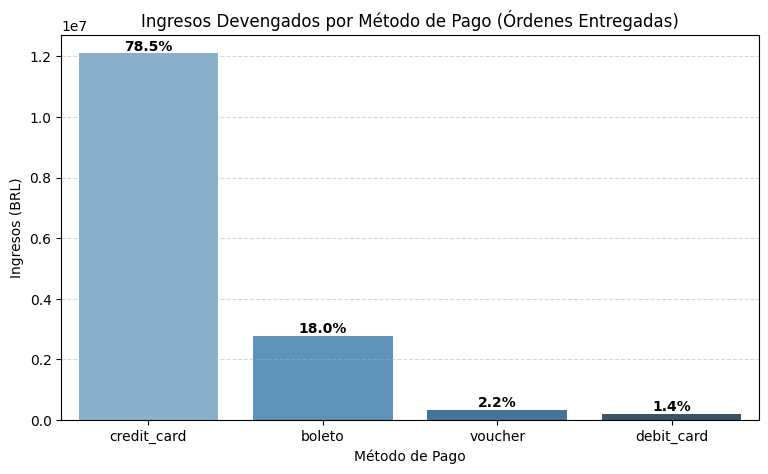

In [3]:
# Prueba 3: Devengado (Aprobado en mes t, entregado en mes t+1)
q_devengado = """
WITH pagos_por_orden AS (
    SELECT order_id, ROUND(SUM(payment_value), 2) AS total_pagado
    FROM payments GROUP BY order_id
)
SELECT strftime('%Y-%m', o.order_approved_at) AS periodo_aprobacion,
       COUNT(o.order_id) AS ordenes_diferidas,
       ROUND(SUM(p.total_pagado), 2) AS ingresos_diferidos_brl
FROM orders o
INNER JOIN pagos_por_orden p ON o.order_id = p.order_id
WHERE o.order_status = 'delivered'
  AND o.order_approved_at IS NOT NULL
  AND o.order_delivered_customer_date IS NOT NULL
  AND strftime('%Y-%m', o.order_delivered_customer_date) > strftime('%Y-%m', o.order_approved_at)
GROUP BY periodo_aprobacion
ORDER BY periodo_aprobacion;
"""
df_devengado = pd.read_sql_query(q_devengado, conn)
print(f"Total órdenes con corte intermensual: {df_devengado['ordenes_diferidas'].sum():,} | Monto total diferido: R$ {df_devengado['ingresos_diferidos_brl'].sum():,.2f}")

# Mix de ingresos reales (filtrando exclusivamente órdenes entregadas)
q_mix_pagos = """
SELECT p.payment_type,
       ROUND(SUM(p.payment_value), 2) AS ingreso_devengado_brl,
       ROUND(SUM(p.payment_value) * 100.0 / SUM(SUM(p.payment_value)) OVER (), 2) AS participacion_pct
FROM payments p
INNER JOIN orders o ON p.order_id = o.order_id
WHERE o.order_status = 'delivered'
GROUP BY p.payment_type
ORDER BY ingreso_devengado_brl DESC;
"""
df_mix_pagos = pd.read_sql_query(q_mix_pagos, conn)
display(df_mix_pagos)

# Gráfico 1: Ingresos devengados por método de pago
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=df_mix_pagos, x="payment_type", y="ingreso_devengado_brl", palette="Blues_d", hue="payment_type", legend=False)
for idx, row in df_mix_pagos.iterrows():
    ax.text(idx, row["ingreso_devengado_brl"], f"{row['participacion_pct']:.1f}%", ha="center", va="bottom", fontweight="bold")
plt.title("Ingresos Devengados por Método de Pago (Órdenes Entregadas)")
plt.xlabel("Método de Pago")
plt.ylabel("Ingresos (BRL)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.savefig(os.path.join(DOCS_IMG_DIR, "grafico_metodos_pago.png"), dpi=150, bbox_inches="tight")
plt.show()

Celda 4 — Prueba Operativa 4: SLA Logístico y Tasa Normalizada de Demora por Estado

,estado,total_entregas,lead_time_promedio_dias,demoras_criticas_30d,tasa_demora_critica_pct,entregas_fuera_plazo,tasa_fuera_plazo_pct
0,AM,145,26.0,45,31.03,4,2.76
1,RR,41,29.0,12,29.27,5,12.20
2,AL,397,24.0,96,24.18,85,21.41
3,PA,946,23.3,196,20.72,106,11.21
4,AP,67,26.7,13,19.40,2,2.99
5,SE,335,21.0,50,14.93,51,15.22
6,MA,717,21.1,105,14.64,125,17.43
7,PB,517,20.0,73,14.12,54,10.44
8,CE,1279,20.8,178,13.92,176,13.76
9,RN,474,18.8,58,12.24,44,9.28


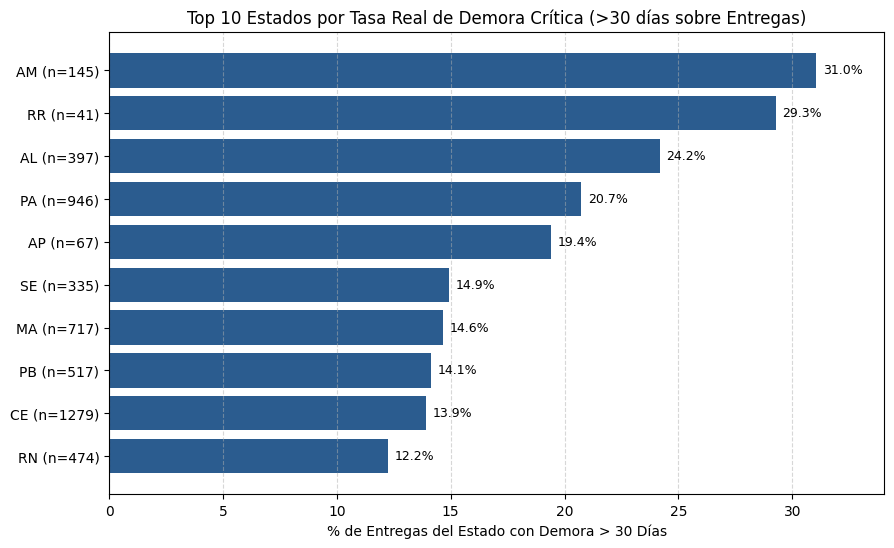

In [4]:
q_sla_estados = """
WITH metricas_entrega AS (
    SELECT c.customer_state AS estado,
           o.order_id,
           CAST(julianday(o.order_delivered_customer_date) - julianday(o.order_purchase_timestamp) AS INTEGER) AS lead_time_dias,
           CASE WHEN CAST(julianday(o.order_delivered_customer_date) - julianday(o.order_purchase_timestamp) AS INTEGER) > 30 THEN 1 ELSE 0 END AS es_demora_critica,
           CASE WHEN date(o.order_delivered_customer_date) > date(o.order_estimated_delivery_date) THEN 1 ELSE 0 END AS es_fuera_de_plazo
    FROM orders o
    INNER JOIN customers c ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered' AND o.order_delivered_customer_date IS NOT NULL
)
SELECT estado,
       COUNT(order_id) AS total_entregas,
       ROUND(AVG(lead_time_dias), 1) AS lead_time_promedio_dias,
       SUM(es_demora_critica) AS demoras_criticas_30d,
       ROUND(SUM(es_demora_critica) * 100.0 / COUNT(order_id), 2) AS tasa_demora_critica_pct,
       SUM(es_fuera_de_plazo) AS entregas_fuera_plazo,
       ROUND(SUM(es_fuera_de_plazo) * 100.0 / COUNT(order_id), 2) AS tasa_fuera_plazo_pct
FROM metricas_entrega
GROUP BY estado
ORDER BY tasa_demora_critica_pct DESC, total_entregas DESC;
"""
df_sla_estados = pd.read_sql_query(q_sla_estados, conn)
display(df_sla_estados.head(10))

# Gráfico 2: Top 10 Estados por Tasa Real de Demora Crítica (>30 días) incluyendo tamaño muestral (n)
top10_sla = df_sla_estados.head(10).sort_values("tasa_demora_critica_pct", ascending=True).copy()
top10_sla["etiqueta"] = top10_sla["estado"] + " (n=" + top10_sla["total_entregas"].astype(str) + ")"

plt.figure(figsize=(10, 6))
bars = plt.barh(top10_sla["etiqueta"], top10_sla["tasa_demora_critica_pct"], color="#2b5c8f")
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.3, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va="center", fontsize=9)
plt.title("Top 10 Estados por Tasa Real de Demora Crítica (>30 días sobre Entregas)")
plt.xlabel("% de Entregas del Estado con Demora > 30 Días")
plt.xlim(0, top10_sla["tasa_demora_critica_pct"].max() + 3)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.savefig(os.path.join(DOCS_IMG_DIR, "grafico_demoras_geograficas.png"), dpi=150, bbox_inches="tight")
plt.show()

Celda 5 — Exportación del Reporte Ejecutivo Multi-Hoja a Excel

In [5]:
total_entregadas = int(df_sla_estados["total_entregas"].sum())
total_demoras_30d = int(df_sla_estados["demoras_criticas_30d"].sum())
total_fuera_plazo = int(df_sla_estados["entregas_fuera_plazo"].sum())
tasa_global_30d = round(total_demoras_30d / total_entregadas * 100, 2)
tasa_global_sla = round(total_fuera_plazo / total_entregadas * 100, 2)
monto_contingencia = float(df_cancelados_cobrados["monto_expuesto_reembolso"].sum())
ordenes_contingencia = int(df_cancelados_cobrados["ordenes_afectadas"].sum())

df_resumen = pd.DataFrame({
    "Indicador de Auditoría": [
        "Total de Órdenes Auditadas",
        "Total de Órdenes Entregadas (Base SLA)",
        "Entregas sin Respaldo de Pago (Prueba 1A)",
        "Registros de Pago con Importe <= 0 (Prueba 1B)",
        "Órdenes Canceladas/No Disp. con Cobro (Prueba 2)",
        "Monto Expuesto a Reembolso (BRL)",
        "Pedidos con Demora Crítica >30 días",
        "Tasa Global de Demora Crítica (>30d / Entregadas)",
        "Tasa Global Incumplimiento Fecha Prometida (SLA)"
    ],
    "Resultado": [
        f"{len(df_orders):,}",
        f"{total_entregadas:,}",
        f"{len(df_sin_pago)}",
        f"{len(df_pagos_cero)}",
        f"{ordenes_contingencia:,}",
        f"R$ {monto_contingencia:,.2f}",
        f"{total_demoras_30d:,}",
        f"{tasa_global_30d:.2f}%",
        f"{tasa_global_sla:.2f}%"
    ]
})

display(df_resumen)

excel_path = os.path.join(OUTPUTS_DIR, "reporte_auditoria_olist.xlsx")
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    df_resumen.to_excel(writer, sheet_name="Resumen_Ejecutivo", index=False)
    df_sla_estados.to_excel(writer, sheet_name="SLA_Por_Estado", index=False)
    df_detalle_cancelados.to_excel(writer, sheet_name="Cancelados_Cobrados", index=False)
    df_devengado.to_excel(writer, sheet_name="Corte_Devengado", index=False)

conn.close()
print(f"Reporte multi-hoja exportado en: {excel_path}")

,Indicador de Auditoría,Resultado
0,Total de Órdenes Auditadas,"99,441"
1,Total de Órdenes Entregadas (Base SLA),"96,470"
2,Entregas sin Respaldo de Pago (Prueba 1A),1
3,Registros de Pago con Importe <= 0 (Prueba 1B),9
4,Órdenes Canceladas/No Disp. con Cobro (Prueba 2),"1,231"
5,Monto Expuesto a Reembolso (BRL),"R$ 269,735.11"
6,Pedidos con Demora Crítica >30 días,"4,117"
7,Tasa Global de Demora Crítica (>30d / Entregadas),4.27%
8,Tasa Global Incumplimiento Fecha Prometida (SLA),6.77%


Reporte multi-hoja exportado en: C:\Dev\DataPortfolio\Proyecto_Olist\outputs\reporte_auditoria_olist.xlsx


## 📋 Recomendaciones de Control Interno

### Integridad Financiera y Contingencias
- **Bloqueo post-entrega:** Implementar una validación automática que impida marcar órdenes como `delivered` sin un registro de cobro acreditado (se detectó 1 orden entregada sin pago: `bfbd0f9bdef84302105ad712db648a6c`) y auditar los 9 registros con importe `<= 0`.
- **Conciliación de pasivos por reembolso:** Cruzar las **1.231 órdenes canceladas o no disponibles con cobro** (**R$ 269.735,11**) contra el auxiliar de devoluciones emitidas para asegurar que no queden saldos pendientes de reintegro a clientes.

### Corte de Operaciones (Devengado)
- **Asiento de cierre mensual:** Automatizar la reclasificación contable como *Anticipos de Clientes / Ingresos Diferidos* de aquellas operaciones aprobadas en un mes calendario pero entregadas en el período siguiente (**34.881 órdenes por R$ 5.929.539,13** acumuladas).

### Performance Logística y SLA
- **Revisión de operadores en Norte y Nordeste:** Al normalizar por volumen de entregas, los mayores cuellos de botella se concentran en **Amazonas (31,03%)**, **Roraima (29,27%)** y **Alagoas (24,18%)**. Se recomienda renegociar acuerdos logísticos en esa región y revisar el incumplimiento contractual de fecha prometida, liderado por **Alagoas (21,41%)** y **Maranhão (17,43%)**.